# Contract-Confound Robustness

This notebook measures the association between address category and contract status, evaluates compact contract/outbound baselines, and runs account-type-controlled follow-up experiments. Contract status comes from public Ethereum `eth_getCode` responses stored with query provenance.

## Setup and stage controls

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display


def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "00_data_graph").exists() and (candidate / "06_robustness_audit").exists():
            return candidate
    raise FileNotFoundError("Project root could not be located")


ROOT = find_project_root(Path.cwd().resolve())
MODULE_DIR = ROOT / "06_robustness_audit" / "02_contract_confound"
RERUN_DIR = MODULE_DIR / "rerun_validation"
STATUS_DIR = MODULE_DIR / "contract_status"
RUN_CORE_ANALYSIS = False
RUN_FOLLOWUP_ANALYSIS = False

print(f"Project root: {ROOT}")
print(f"Frozen evidence: {MODULE_DIR}")
print(f"Core rerun enabled: {RUN_CORE_ANALYSIS}")
print(f"Follow-up rerun enabled: {RUN_FOLLOWUP_ANALYSIS}")


Project root: E:\dissertation
Frozen evidence: E:\dissertation\06_robustness_audit\02_contract_confound
Core rerun enabled: False
Follow-up rerun enabled: False


## Contract-status provenance

The frozen `contract_query_log.json` predates the corrected query utility. Its `query_run_recorded_at_utc` field records a follow-up analysis run, so the timestamp of the original status query is unavailable. The independent July recheck reproduced 500/500 statuses while recording the chain head. Current query utilities pin every `eth_getCode` request to one recorded block and stop before writing incomplete results.

In [2]:
status = pd.read_csv(STATUS_DIR / "seed_is_contract.csv")
with (STATUS_DIR / "contract_query_log.json").open(encoding="utf-8") as handle:
    query_log = json.load(handle)
with (STATUS_DIR / "contract_reproducibility_metadata.json").open(encoding="utf-8") as handle:
    reproducibility = json.load(handle)
display(pd.Series(query_log, name="value").to_frame())
display(pd.Series(reproducibility, name="value").to_frame())
print(status.groupby("is_contract").size().rename("n_addresses"))


,value
rpc_endpoint,https://ethereum-rpc.publicnode.com
method,eth_getCode
empty_bytecode_rule,"result == ""0x"" (or length <= 2) => EOA; otherw..."
query_run_recorded_at_utc,2026-08-05T13:17:33.312284+00:00
n_addresses_queried,500
n_rpc_success,500
n_rpc_failed_after_retries,0
retry_policy,"up to 3 attempts per address, 1.5s * attempt_n..."
coverage_pct,100.0


,value
rpc_url,https://ethereum-rpc.publicnode.com
query_started_utc,2026-07-12T12:40:53.151867+00:00
query_finished_utc,2026-07-12T12:43:24.788818+00:00
block_parameter_used,latest
chain_head_block_number_at_query_start,25516603
n_addresses_rechecked,500
n_matches_vs_original_is_contract_csv,500
match_rate,1.0
n_mismatches,0


is_contract
False    314
True     186
Name: n_addresses, dtype: int64


## Category ratios and compact baselines

In [3]:
BASELINE_DIR = MODULE_DIR / "baseline_checks"
for filename in [
    "contract_ratio_by_label.csv",
    "contract_ratio_by_label_active.csv",
    "minimal_baseline_summary.csv",
    "outbound_ablation_summary.csv",
    "outbound_ablation_paired_test.csv",
    "eoa_only_cex_vs_mev_summary.csv",
]:
    print(f"\n{filename}")
    display(pd.read_csv(BASELINE_DIR / filename))



contract_ratio_by_label.csv


,label,n_contract,n_total,contract_ratio
0,CEX,2,51,0.0392
1,DeFi,150,150,1.0000
2,Malicious_MEV,34,299,0.1137



contract_ratio_by_label_active.csv


,label,n_contract,n_total,contract_ratio
0,CEX,2,51,0.0392
1,DeFi,86,86,1.0000
2,Malicious_MEV,34,299,0.1137



minimal_baseline_summary.csv


,model,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,balanced_accuracy_std
0,LogisticRegression,0.5938,0.0581,0.6271,0.0417
1,RandomForest,0.9169,0.0254,0.9239,0.0288
2,XGBoost,0.9101,0.0239,0.9217,0.0280


... (2 outputs left out)


outbound_ablation_paired_test.csv


,model,full_mean,no_outbound_mean,mean_diff,paired_t_stat,paired_p_value
0,LogisticRegression,0.8847,0.8966,-0.0119,-0.7190,0.5119
1,RandomForest,0.9000,0.8831,0.0168,1.4261,0.2270
2,XGBoost,0.9065,0.9152,-0.0088,-1.7491,0.1552



eoa_only_cex_vs_mev_summary.csv


,model,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,balanced_accuracy_std
0,LogisticRegression,0.9238,0.0339,0.9257,0.0185
1,RandomForest,0.9320,0.0393,0.9048,0.0662
2,XGBoost,0.9228,0.0708,0.9172,0.0843


## EOA-controlled feature ablation

,feature_set,model,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,balanced_accuracy_std
0,embedding,LogisticRegression,0.8850,0.0359,0.9342,0.0248
1,embedding,RandomForest,0.8421,0.0986,0.7996,0.1036
2,embedding,XGBoost,0.8686,0.0666,0.8380,0.0822
3,graph_structural,LogisticRegression,0.6590,0.0671,0.7394,0.1093
4,graph_structural,RandomForest,0.8383,0.0856,0.8131,0.1127
5,graph_structural,XGBoost,0.8244,0.0783,0.8284,0.0904
6,hand_crafted,LogisticRegression,0.9238,0.0339,0.9257,0.0185
7,hand_crafted,RandomForest,0.9320,0.0393,0.9048,0.0662
8,hand_crafted,XGBoost,0.9228,0.0708,0.9172,0.0843
9,hand_crafted_embedding,LogisticRegression,0.9238,0.0443,0.9268,0.0431


,comparison,model,mean_diff,paired_t_stat,paired_p_value,n_folds_improved
0,hand_crafted vs transaction_behaviour,LogisticRegression,-0.0118,-0.9076,0.4154,1
1,hand_crafted vs transaction_behaviour,RandomForest,0.0037,0.2753,0.7967,2
2,hand_crafted vs transaction_behaviour,XGBoost,-0.0188,-1.1686,0.3075,1
3,hand_crafted_embedding vs hand_crafted,LogisticRegression,0.0000,0.0009,0.9994,2
4,hand_crafted_embedding vs hand_crafted,RandomForest,-0.0129,-1.6301,0.1784,0
5,hand_crafted_embedding vs hand_crafted,XGBoost,-0.0024,-0.1279,0.9044,3


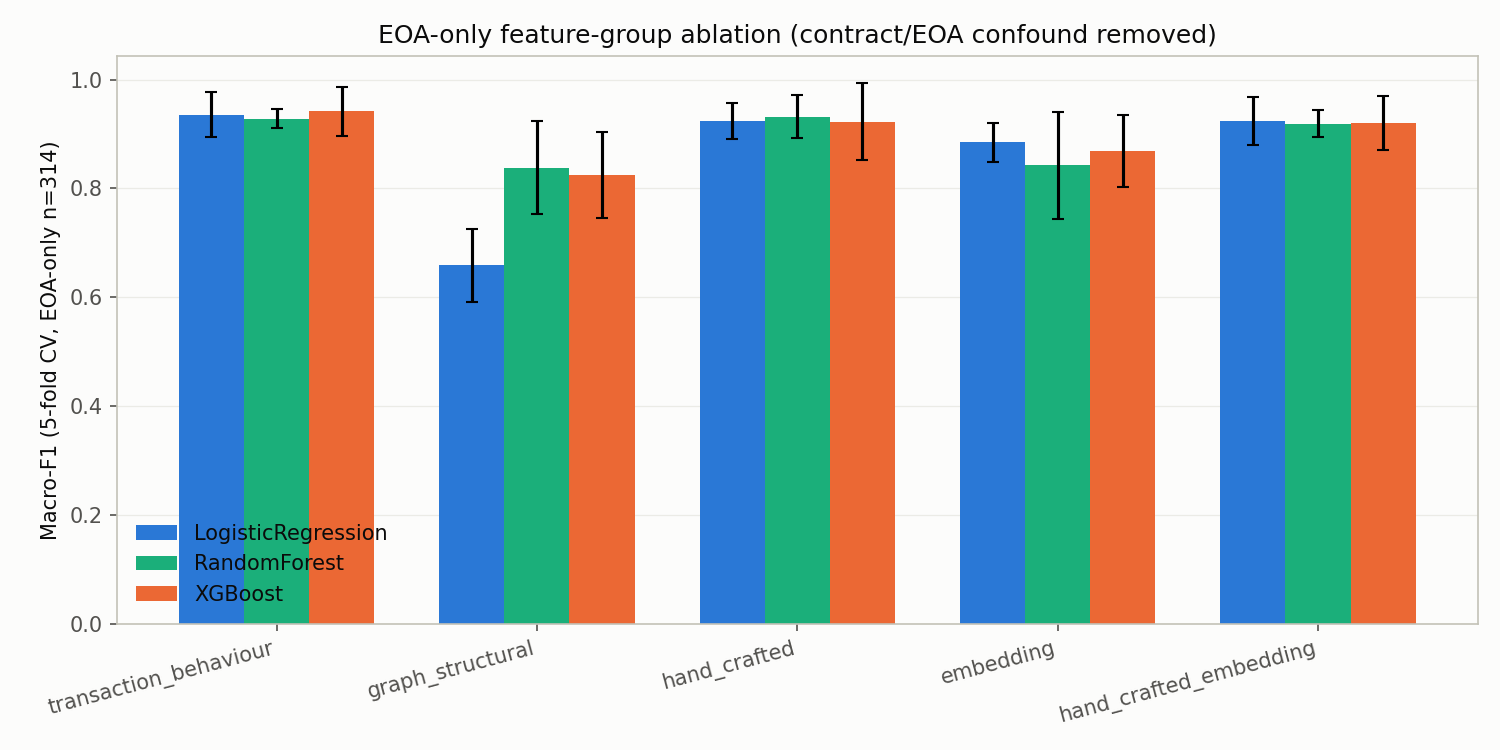

In [4]:
EOA_DIR = MODULE_DIR / "eoa_checks"
display(pd.read_csv(EOA_DIR / "eoa_only_summary.csv"))
display(pd.read_csv(EOA_DIR / "eoa_only_paired_differences.csv"))
display(Image(filename=str(EOA_DIR / "eoa_only_feature_ablation.png")))


## Contract-only repeated balanced comparison

,feature_set,model,macro_f1_mean_of_means,macro_f1_std_across_repeats,p5,p95
0,coarse,LogisticRegression,0.8706,0.0088,0.8545,0.8805
1,coarse,RandomForest,0.8515,0.0270,0.8121,0.8972
2,coarse,XGBoost,0.8517,0.0264,0.8117,0.8980
3,embedding,LogisticRegression,0.8519,0.0352,0.7950,0.9038
4,embedding,RandomForest,0.8014,0.0321,0.7526,0.8523
5,embedding,XGBoost,0.7906,0.0432,0.7173,0.8682
6,graph_structural,LogisticRegression,0.7905,0.0289,0.7500,0.8351
7,graph_structural,RandomForest,0.8523,0.0285,0.8031,0.8942
8,graph_structural,XGBoost,0.8362,0.0335,0.7811,0.8802
9,hand_crafted,LogisticRegression,0.8664,0.0223,0.8321,0.9037


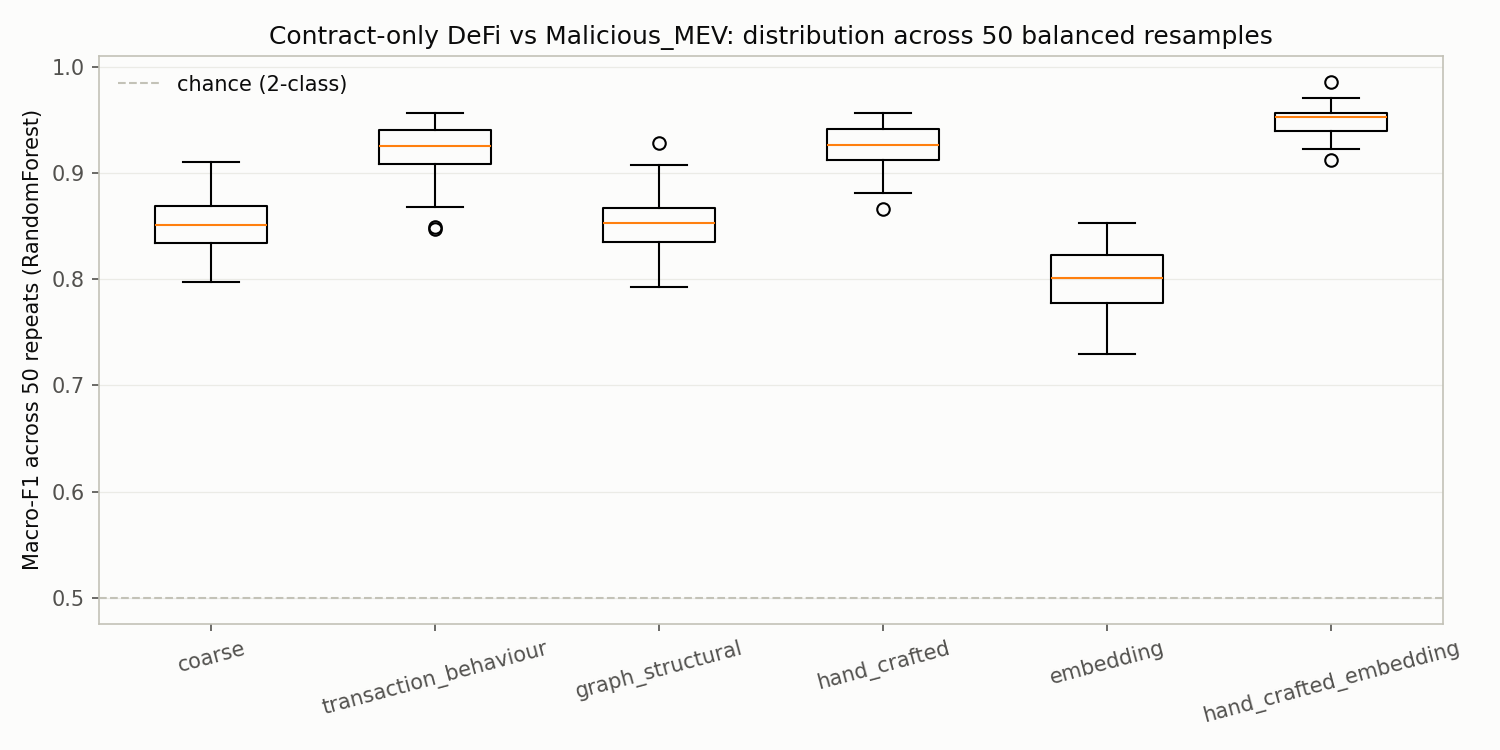

In [5]:
CONTRACT_ONLY_DIR = MODULE_DIR / "contract_only_checks"
display(pd.read_csv(CONTRACT_ONLY_DIR / "contract_only_summary.csv"))
display(Image(filename=str(CONTRACT_ONLY_DIR / "contract_only_macro_f1_distribution.png")))


## Interpretation

Contract status is strongly associated with the stored role labels, especially for DeFi. The EOA-only and contract-only analyses therefore provide the account-type-controlled evidence used to qualify RQ1.

## Optional core-analysis rerun

Set `RUN_CORE_ANALYSIS = True` in the setup cell and run all cells to recompute this stage. New artifacts are written to `rerun_validation/`, preserving the frozen dissertation evidence.

### Imports and helper functions

In [6]:
if RUN_CORE_ANALYSIS:
    import sys
    sys.argv = [sys.argv[0]]
    import sys
    import json
    import time
    from pathlib import Path

    import numpy as np
    import pandas as pd
    import requests

    from sklearn.model_selection import StratifiedKFold
    from sklearn.linear_model import LogisticRegression
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import StandardScaler, LabelEncoder
    from sklearn.metrics import f1_score, balanced_accuracy_score
    from sklearn.utils.class_weight import compute_sample_weight
    from xgboost import XGBClassifier


### 0. Setup

In [7]:
if RUN_CORE_ANALYSIS:
    # Confound check: active DeFi seeds have out_edge_count == 100% zero (never
    # initiate transactions), while CEX/Malicious_MEV mostly do. Since DeFi labels
    # are almost all smart contracts (protocols, pools) and CEX/MEV labels are a
    # mix of EOA wallets and bot contracts, the classifier may largely be learning
    # "is this a contract" (which correlates near-perfectly with is DeFi) rather
    # than genuine economic behaviour differences between the three categories.
    # This script gets ground-truth is_contract via eth_getCode (bytecode length
    # > 0 => contract) for all 500 seeds and re-runs the core classification
    # comparisons with that confound controlled for.

    RANDOM_STATE = 42
    N_SPLITS = 5
    LABEL_COL = "label"
    LABEL_ORDER = ["CEX", "DeFi", "Malicious_MEV"]
    MODEL_ORDER = ["LogisticRegression", "RandomForest", "XGBoost"]

    # Optional CLI args: feat_file edges_file out_subdir contract_cache_dir.
    PROJECT_ROOT = ROOT
    FEATURE_DIR = PROJECT_ROOT / "02_feature_engineering" / "feature_engineering"
    DEFAULT_CONTRACT_DIR = RERUN_DIR
    FEAT_FILE = Path(sys.argv[1]) if len(sys.argv) > 1 else FEATURE_DIR / "seed_feature_matrix_reconstructed.csv"
    EDGES_FILE = Path(sys.argv[2]) if len(sys.argv) > 2 else PROJECT_ROOT / "00_data_graph" / "data" / "main" / "raw_edges_reconstructed.csv"
    OUT_SUBDIR = Path(sys.argv[3]) if len(sys.argv) > 3 else DEFAULT_CONTRACT_DIR
    CONTRACT_CACHE_DIR = STATUS_DIR
    FEATURE_GROUPS_FILE = FEATURE_DIR / "feature_groups.json"

    RPC_URL = "https://ethereum-rpc.publicnode.com"
    OUT_DIR = Path(OUT_SUBDIR)
    OUT_DIR.mkdir(parents=True, exist_ok=True)


    def get_code(address, retries=3):
        payload = {"jsonrpc": "2.0", "method": "eth_getCode", "params": [address, "latest"], "id": 1}
        for attempt in range(retries):
            try:
                r = requests.post(RPC_URL, json=payload, timeout=15)
                data = r.json()
                if "result" in data:
                    return data["result"]
            except Exception as e:
                pass
            time.sleep(1.5 * (attempt + 1))
        return None


    def build_cv_results(X, y, group_label, feature_set_name):
        label_encoder = LabelEncoder().fit(sorted(set(y)))
        rows = []
        for model_name in MODEL_ORDER:
            skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
            for fold_i, (train_idx, test_idx) in enumerate(skf.split(X, y)):
                X_train, X_test = X[train_idx], X[test_idx]
                y_train, y_test = y[train_idx], y[test_idx]

                if model_name == "LogisticRegression":
                    model = Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))])
                    model.fit(X_train, y_train)
                    y_pred = model.predict(X_test)
                elif model_name == "RandomForest":
                    model = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)
                    model.fit(X_train, y_train)
                    y_pred = model.predict(X_test)
                else:
                    model = XGBClassifier(n_estimators=300, random_state=RANDOM_STATE, eval_metric="mlogloss", n_jobs=-1)
                    y_train_enc = label_encoder.transform(y_train)
                    sample_weight = compute_sample_weight("balanced", y_train_enc)
                    model.fit(X_train, y_train_enc, sample_weight=sample_weight)
                    y_pred = label_encoder.inverse_transform(model.predict(X_test))

                rows.append({
                    "group": group_label, "feature_set": feature_set_name, "model": model_name, "fold": fold_i,
                    "macro_f1": f1_score(y_test, y_pred, average="macro", zero_division=0),
                    "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
                })
        return pd.DataFrame(rows)


    def clean_address(x):
        if pd.isna(x):
            return np.nan
        return str(x).strip().lower()


### 1. Query is_contract for all 500 seeds

In [8]:
if RUN_CORE_ANALYSIS:

    feat = pd.read_csv(FEAT_FILE)
    feat["address"] = feat["address"].map(clean_address)
    cache_path = Path(CONTRACT_CACHE_DIR) / "seed_is_contract.csv"
    cache_path.parent.mkdir(parents=True, exist_ok=True)

    if cache_path.exists():
        contract_df = pd.read_csv(cache_path)
        print(f"Loaded cached is_contract results for {len(contract_df)} seeds from {cache_path}")
    else:
        print(f"Querying eth_getCode for {len(feat)} seeds via {RPC_URL} ...")
        results = []
        for i, addr in enumerate(feat["address"]):
            code = get_code(addr)
            is_contract = (code is not None) and (code != "0x") and (len(code) > 2)
            results.append({"address": addr, "bytecode_length": (len(code) - 2) // 2 if code and code != "0x" else 0, "is_contract": is_contract, "rpc_ok": code is not None})
            if (i + 1) % 50 == 0:
                print(f"  {i + 1}/{len(feat)} queried")
        contract_df = pd.DataFrame(results)
        contract_df.to_csv(cache_path, index=False)
        print(f"Saved {cache_path}")

    required_contract_columns = {"address", "is_contract", "bytecode_length", "rpc_ok"}
    missing_columns = required_contract_columns.difference(contract_df.columns)
    if missing_columns:
        raise ValueError(f"Contract cache is missing columns: {sorted(missing_columns)}")

    contract_df["address"] = contract_df["address"].map(clean_address)
    if contract_df["address"].isna().any() or contract_df["address"].duplicated().any():
        raise ValueError("Contract cache contains missing or duplicate addresses")

    missing_addresses = set(feat["address"]) - set(contract_df["address"])
    extra_addresses = set(contract_df["address"]) - set(feat["address"])
    if missing_addresses or extra_addresses:
        raise ValueError(
            "Contract cache address coverage does not match the feature matrix: "
            f"missing={len(missing_addresses)}, extra={len(extra_addresses)}"
        )

    failed = int((~contract_df["rpc_ok"].astype(bool)).sum())
    if failed:
        raise RuntimeError(
            f"Contract status is unresolved for {failed} addresses; rerun the RPC query "
            "before using the cache in an analysis."
        )
    if contract_df["is_contract"].isna().any():
        raise ValueError("Contract cache contains unresolved is_contract values")

    feat = feat.merge(contract_df[["address", "is_contract", "bytecode_length"]], on="address", how="left")
    if feat["is_contract"].isna().any():
        raise ValueError("Contract status merge produced missing values")
    feat["is_contract"] = feat["is_contract"].astype(bool)


### 2. Contract/EOA ratio per class

In [9]:
if RUN_CORE_ANALYSIS:

    ratio_table = feat.groupby(LABEL_COL)["is_contract"].agg(["sum", "count", "mean"]).rename(
        columns={"sum": "n_contract", "count": "n_total", "mean": "contract_ratio"}
    ).reindex(LABEL_ORDER).round(4)
    ratio_table.to_csv(OUT_DIR / "contract_ratio_by_label.csv")
    print(f"\n=== Contract/EOA ratio by label (all 500 seeds) ===\n{ratio_table.to_string()}")

    active = feat[feat["is_active"]].copy()
    ratio_table_active = active.groupby(LABEL_COL)["is_contract"].agg(["sum", "count", "mean"]).rename(
        columns={"sum": "n_contract", "count": "n_total", "mean": "contract_ratio"}
    ).reindex(LABEL_ORDER).round(4)
    ratio_table_active.to_csv(OUT_DIR / "contract_ratio_by_label_active.csv")
    print(f"\n=== Contract/EOA ratio by label (436 active seeds only) ===\n{ratio_table_active.to_string()}")


### 3. Minimal baseline: is_contract + has_out_edge + out_tx_count only

In [10]:
if RUN_CORE_ANALYSIS:

    minimal_cols = ["is_contract", "has_out_edge", "out_tx_count"]
    X_min = active[minimal_cols].astype(float).to_numpy()
    y = active[LABEL_COL].to_numpy()

    minimal_fold_df = build_cv_results(X_min, y, "minimal_baseline", "is_contract+has_out_edge+out_tx_count")
    minimal_summary = minimal_fold_df.groupby("model")[["macro_f1", "balanced_accuracy"]].agg(["mean", "std"])
    minimal_summary.columns = ["_".join(c) for c in minimal_summary.columns]
    minimal_summary = minimal_summary.reset_index().round(4)
    minimal_summary.to_csv(OUT_DIR / "minimal_baseline_summary.csv", index=False)
    print(f"\n=== Minimal 3-feature baseline (is_contract + has_out_edge + out_tx_count) ===\n{minimal_summary.to_string(index=False)}")


### 4. Full hand_crafted set with ALL outbound-direction features removed

In [11]:
if RUN_CORE_ANALYSIS:

    with open(FEATURE_GROUPS_FILE) as f:
        feature_groups = json.load(f)
    handcrafted_cols = list(feature_groups["transaction_behaviour"] + feature_groups["graph_structural"])

    edges = pd.read_csv(EDGES_FILE)
    edges["source"] = edges["source"].apply(clean_address)
    edges["target"] = edges["target"].apply(clean_address)
    edges = edges.dropna(subset=["source", "target"])
    import networkx as nx
    G = nx.from_pandas_edgelist(edges, source="source", target="target", edge_attr=["tx_count"], create_using=nx.DiGraph())
    pagerank_rank = pd.Series(nx.pagerank(G)).rank(pct=True)
    pagerank_weighted_rank = pd.Series(nx.pagerank(G, weight="tx_count")).rank(pct=True)
    feat["pagerank_rank"] = feat["address"].map(pagerank_rank).fillna(0.0)
    feat["pagerank_weighted_rank"] = feat["address"].map(pagerank_weighted_rank).fillna(0.0)
    for col in ["pagerank", "pagerank_weighted", "log_pagerank", "log_pagerank_weighted"]:
        if col in handcrafted_cols:
            handcrafted_cols.remove(col)
    handcrafted_cols += ["pagerank_rank", "pagerank_weighted_rank"]

    active = feat[feat["is_active"]].copy()  # refresh with pagerank_rank columns

    OUTBOUND_COLS = [c for c in handcrafted_cols if c.startswith("out_") or c.startswith("log_out_") or c == "weighted_out_degree" or c == "out_degree" or c == "has_out_edge"]
    no_outbound_cols = [c for c in handcrafted_cols if c not in OUTBOUND_COLS]
    print(f"\nRemoving {len(OUTBOUND_COLS)} outbound-direction features: {OUTBOUND_COLS}")
    print(f"Remaining {len(no_outbound_cols)} features: {no_outbound_cols}")

    X_full = active[handcrafted_cols].astype(float).to_numpy()
    X_no_out = active[no_outbound_cols].astype(float).to_numpy()
    y = active[LABEL_COL].to_numpy()

    full_fold_df = build_cv_results(X_full, y, "outbound_ablation", "hand_crafted_full")
    no_out_fold_df = build_cv_results(X_no_out, y, "outbound_ablation", "hand_crafted_no_outbound")

    outbound_fold_df = pd.concat([full_fold_df, no_out_fold_df], ignore_index=True)
    outbound_summary = outbound_fold_df.groupby(["feature_set", "model"])[["macro_f1", "balanced_accuracy"]].agg(["mean", "std"])
    outbound_summary.columns = ["_".join(c) for c in outbound_summary.columns]
    outbound_summary = outbound_summary.reset_index().round(4)
    outbound_summary.to_csv(OUT_DIR / "outbound_ablation_summary.csv", index=False)
    outbound_fold_df.to_csv(OUT_DIR / "outbound_ablation_fold_scores.csv", index=False)
    print(f"\n=== hand_crafted_full vs hand_crafted_no_outbound (all outbound-direction features removed) ===\n{outbound_summary.to_string(index=False)}")

    from scipy import stats
    paired_rows = []
    for model_name in MODEL_ORDER:
        full = full_fold_df[full_fold_df.model == model_name].sort_values("fold")["macro_f1"].values
        no_out = no_out_fold_df[no_out_fold_df.model == model_name].sort_values("fold")["macro_f1"].values
        diff = full - no_out
        t_stat, p_val = stats.ttest_rel(full, no_out)
        paired_rows.append({"model": model_name, "full_mean": full.mean(), "no_outbound_mean": no_out.mean(),
                             "mean_diff": diff.mean(), "paired_t_stat": t_stat, "paired_p_value": p_val})
    paired_df = pd.DataFrame(paired_rows).round(4)
    paired_df.to_csv(OUT_DIR / "outbound_ablation_paired_test.csv", index=False)
    print(f"\n=== Paired test: full vs no-outbound (same 5 folds) ===\n{paired_df.to_string(index=False)}")


### 5. Sub-experiment: CEX vs Malicious_MEV only, restricted to EOA addresses (is_contract == False)

In [12]:
if RUN_CORE_ANALYSIS:

    eoa_only = active[(~active["is_contract"]) & (active[LABEL_COL].isin(["CEX", "Malicious_MEV"]))].copy()
    print(f"\nEOA-only CEX vs Malicious_MEV subset: {len(eoa_only)} seeds, {dict(eoa_only[LABEL_COL].value_counts())}")

    X_eoa = eoa_only[handcrafted_cols].astype(float).to_numpy()
    y_eoa = eoa_only[LABEL_COL].to_numpy()

    eoa_fold_df = build_cv_results(X_eoa, y_eoa, "eoa_only_binary", "hand_crafted_full")
    eoa_summary = eoa_fold_df.groupby("model")[["macro_f1", "balanced_accuracy"]].agg(["mean", "std"])
    eoa_summary.columns = ["_".join(c) for c in eoa_summary.columns]
    eoa_summary = eoa_summary.reset_index().round(4)
    eoa_summary.to_csv(OUT_DIR / "eoa_only_cex_vs_mev_summary.csv", index=False)
    print(f"\n=== CEX vs Malicious_MEV, EOA-only subset (contract-type confound removed) ===\n{eoa_summary.to_string(index=False)}")

    print("\n=== Contract/EOA confound check complete ===")


## Optional follow-up rerun

Set `RUN_FOLLOWUP_ANALYSIS = True` in the setup cell and run all cells to recompute this stage. New artifacts are written to `rerun_validation/`, preserving the frozen dissertation evidence.

### Imports and helper functions

In [13]:
if RUN_FOLLOWUP_ANALYSIS:
    import sys
    sys.argv = [sys.argv[0]]
    import sys
    import json
    import time
    from datetime import datetime, timezone
    from pathlib import Path

    import numpy as np
    import pandas as pd
    import networkx as nx

    from sklearn.model_selection import StratifiedKFold
    from sklearn.linear_model import LogisticRegression
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import StandardScaler, LabelEncoder
    from sklearn.metrics import (
        f1_score, balanced_accuracy_score, precision_recall_fscore_support, confusion_matrix,
    )
    from sklearn.utils.class_weight import compute_sample_weight
    from xgboost import XGBClassifier


### 0. Setup

In [14]:
if RUN_FOLLOWUP_ANALYSIS:
    # P1 follow-up to contract_confound_check.py's headline finding (DeFi is
    # 100% contracts, 3.9% for CEX, 11.4% for Malicious_MEV). Three sub-experiments:
    #   Follow-up A: EOA-only feature-group ablation -- does the "graph features
    #          add nothing" conclusion survive once the contract/EOA confound is
    #          fully removed?
    #   10.8b) Contract-only DeFi vs Malicious_MEV -- among addresses that are ALL
    #          contracts, is there still a class-specific signal, or does
    #          performance collapse to near-chance once account-type is held fixed?
    #   10.8c) Per-class breakdown of the outbound-feature-removal experiment --
    #          which class's F1 actually moves when out_* features are dropped?

    RANDOM_STATE = 42
    N_SPLITS = 5
    LABEL_COL = "label"
    LABEL_ORDER = ["CEX", "DeFi", "Malicious_MEV"]
    MODEL_ORDER = ["LogisticRegression", "RandomForest", "XGBoost"]

    # Optional CLI args: feat_file edges_file emb_dir out_subdir contract_cache_dir.
    PROJECT_ROOT = ROOT
    FEATURE_DIR = PROJECT_ROOT / "02_feature_engineering" / "feature_engineering"
    DEFAULT_CONTRACT_DIR = RERUN_DIR
    FEAT_FILE = Path(sys.argv[1]) if len(sys.argv) > 1 else FEATURE_DIR / "seed_feature_matrix_reconstructed.csv"
    EDGES_FILE = Path(sys.argv[2]) if len(sys.argv) > 2 else PROJECT_ROOT / "00_data_graph" / "data" / "main" / "raw_edges_reconstructed.csv"
    EMB_DIR = Path(sys.argv[3]) if len(sys.argv) > 3 else PROJECT_ROOT / "03_unsupervised" / "node2vec_results"
    OUT_SUBDIR = Path(sys.argv[4]) if len(sys.argv) > 4 else DEFAULT_CONTRACT_DIR
    CONTRACT_CACHE_DIR = STATUS_DIR
    FEATURE_GROUPS_FILE = FEATURE_DIR / "feature_groups.json"

    OUT_DIR = Path(OUT_SUBDIR)
    OUT_DIR.mkdir(parents=True, exist_ok=True)


    def clean_address(x):
        if pd.isna(x):
            return np.nan
        return str(x).strip().lower()


    def build_cv_fold_scores(X, y, model_order=MODEL_ORDER, n_splits=N_SPLITS, random_state=RANDOM_STATE):
        """Returns (fold_df, oof_pred) -- fold_df has per-fold macro_f1/balanced_accuracy
        per model; oof_pred[model_name] is an out-of-fold prediction array aligned to y."""
        label_encoder = LabelEncoder().fit(sorted(set(y)))
        rows = []
        oof_pred = {}
        for model_name in model_order:
            skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
            y_pred_oof = np.empty(len(y), dtype=object)
            for fold_i, (train_idx, test_idx) in enumerate(skf.split(X, y)):
                X_train, X_test = X[train_idx], X[test_idx]
                y_train, y_test = y[train_idx], y[test_idx]

                if model_name == "LogisticRegression":
                    model = Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=random_state))])
                    model.fit(X_train, y_train)
                    y_pred = model.predict(X_test)
                elif model_name == "RandomForest":
                    model = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=random_state, n_jobs=-1)
                    model.fit(X_train, y_train)
                    y_pred = model.predict(X_test)
                else:
                    model = XGBClassifier(n_estimators=300, random_state=random_state, eval_metric="mlogloss", n_jobs=-1)
                    y_train_enc = label_encoder.transform(y_train)
                    sample_weight = compute_sample_weight("balanced", y_train_enc)
                    model.fit(X_train, y_train_enc, sample_weight=sample_weight)
                    y_pred = label_encoder.inverse_transform(model.predict(X_test))

                y_pred_oof[test_idx] = y_pred
                rows.append({
                    "model": model_name, "fold": fold_i,
                    "macro_f1": f1_score(y_test, y_pred, average="macro", zero_division=0),
                    "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
                })
            oof_pred[model_name] = y_pred_oof
        return pd.DataFrame(rows), oof_pred


### 1. Load data (same construction as 01_classification.ipynb / feature_ablation_shap.ipynb)

In [15]:
if RUN_FOLLOWUP_ANALYSIS:

    feat = pd.read_csv(FEAT_FILE)
    with open(FEATURE_GROUPS_FILE) as f:
        feature_groups = json.load(f)
    txn_cols = list(feature_groups["transaction_behaviour"])
    struct_cols = list(feature_groups["graph_structural"])

    edges = pd.read_csv(EDGES_FILE)
    edges["source"] = edges["source"].apply(clean_address)
    edges["target"] = edges["target"].apply(clean_address)
    edges = edges.dropna(subset=["source", "target"])
    G = nx.from_pandas_edgelist(edges, source="source", target="target", edge_attr=["tx_count"], create_using=nx.DiGraph())
    pagerank_rank = pd.Series(nx.pagerank(G)).rank(pct=True)
    pagerank_weighted_rank = pd.Series(nx.pagerank(G, weight="tx_count")).rank(pct=True)
    feat["pagerank_rank"] = feat["address"].map(pagerank_rank).fillna(0.0)
    feat["pagerank_weighted_rank"] = feat["address"].map(pagerank_weighted_rank).fillna(0.0)
    for col in ["pagerank", "pagerank_weighted", "log_pagerank", "log_pagerank_weighted"]:
        if col in struct_cols:
            struct_cols.remove(col)
    struct_cols += ["pagerank_rank", "pagerank_weighted_rank"]
    handcrafted_cols = txn_cols + struct_cols

    contract_df = pd.read_csv(Path(CONTRACT_CACHE_DIR) / "seed_is_contract.csv")
    contract_df["address"] = contract_df["address"].apply(clean_address)
    required_contract_columns = {"address", "is_contract", "bytecode_length", "rpc_ok"}
    missing_columns = required_contract_columns.difference(contract_df.columns)
    if missing_columns:
        raise ValueError(f"Contract cache is missing columns: {sorted(missing_columns)}")
    if contract_df["address"].isna().any() or contract_df["address"].duplicated().any():
        raise ValueError("Contract cache contains missing or duplicate addresses")
    missing_addresses = set(feat["address"]) - set(contract_df["address"])
    extra_addresses = set(contract_df["address"]) - set(feat["address"])
    if missing_addresses or extra_addresses:
        raise ValueError(
            "Contract cache address coverage does not match the feature matrix: "
            f"missing={len(missing_addresses)}, extra={len(extra_addresses)}"
        )
    failed = int((~contract_df["rpc_ok"].astype(bool)).sum())
    if failed:
        raise RuntimeError(
            f"Contract status is unresolved for {failed} addresses; refresh the cache "
            "before running the confound analysis."
        )
    if contract_df["is_contract"].isna().any():
        raise ValueError("Contract cache contains unresolved is_contract values")
    feat = feat.merge(contract_df[["address", "is_contract", "bytecode_length", "rpc_ok"]], on="address", how="left")
    if feat["is_contract"].isna().any():
        raise ValueError("Contract status merge produced missing values")
    feat["is_contract"] = feat["is_contract"].astype(bool)

    emb = pd.read_csv(f"{EMB_DIR}/seed_node2vec_embeddings.csv")
    emb_cols = [c for c in emb.columns if c.startswith("emb_")]

    active = feat[feat["is_active"]].copy()
    data = active.merge(emb[["address"] + emb_cols], on="address", how="inner")


### 2. RPC query log (P1 technical requirement)

In [16]:
if RUN_FOLLOWUP_ANALYSIS:

    query_log = {
        "rpc_endpoint": "https://ethereum-rpc.publicnode.com",
        "method": "eth_getCode",
        "empty_bytecode_rule": 'result == "0x" (or length <= 2) => EOA; otherwise => contract',
        "analysis_run_recorded_at_utc": datetime.now(timezone.utc).isoformat(),
        "source_query_timestamp_available": False,
        "source_cache": str(Path(CONTRACT_CACHE_DIR) / "seed_is_contract.csv"),
        "n_addresses_queried": int(len(contract_df)),
        "n_rpc_success": int(contract_df["rpc_ok"].sum()),
        "n_rpc_failed_after_retries": int((~contract_df["rpc_ok"]).sum()),
        "retry_policy": "up to 3 attempts per address, 1.5s * attempt_number backoff",
        "coverage_pct": round(100 * contract_df["rpc_ok"].mean(), 2),
    }
    with open(OUT_DIR / "contract_query_log.json", "w") as f:
        json.dump(query_log, f, indent=2)
    print(f"=== RPC query log ===\n{json.dumps(query_log, indent=2)}")
    print(f"Saved {OUT_DIR / 'contract_query_log.json'}")


### 3. EOA-only feature-group ablation

In [17]:
if RUN_FOLLOWUP_ANALYSIS:

    eoa = data[~data["is_contract"]].copy()
    print(f"\nEOA-only sample (active, embeddings available): {len(eoa)} seeds, {dict(eoa[LABEL_COL].value_counts())}")

    X_txn = eoa[txn_cols].to_numpy(dtype=float)
    X_struct = eoa[struct_cols].to_numpy(dtype=float)
    X_hand = eoa[handcrafted_cols].to_numpy(dtype=float)
    X_emb = eoa[emb_cols].to_numpy(dtype=float)
    X_combined = np.hstack([X_hand, X_emb])
    y_eoa = eoa[LABEL_COL].to_numpy()

    eoa_feature_sets = {
        "transaction_behaviour": X_txn, "graph_structural": X_struct, "hand_crafted": X_hand,
        "embedding": X_emb, "hand_crafted_embedding": X_combined,
    }

    eoa_fold_rows = []
    for fs_name, X in eoa_feature_sets.items():
        fold_df, _ = build_cv_fold_scores(X, y_eoa)
        fold_df["feature_set"] = fs_name
        eoa_fold_rows.append(fold_df)
        print(f"EOA-only / {fs_name}: done")

    eoa_fold_df = pd.concat(eoa_fold_rows, ignore_index=True)
    eoa_fold_df.to_csv(OUT_DIR / "eoa_only_cv_scores.csv", index=False)

    eoa_summary = eoa_fold_df.groupby(["feature_set", "model"])[["macro_f1", "balanced_accuracy"]].agg(["mean", "std"])
    eoa_summary.columns = ["_".join(c) for c in eoa_summary.columns]
    eoa_summary = eoa_summary.reset_index().round(4)
    eoa_summary.to_csv(OUT_DIR / "eoa_only_summary.csv", index=False)
    print(f"\n=== EOA-only feature-group ablation (n={len(eoa)}) ===\n{eoa_summary.to_string(index=False)}")

    from scipy import stats
    eoa_paired_rows = []
    for a_name, b_name in [("hand_crafted", "transaction_behaviour"), ("hand_crafted_embedding", "hand_crafted")]:
        for model_name in MODEL_ORDER:
            a = eoa_fold_df[(eoa_fold_df.feature_set == a_name) & (eoa_fold_df.model == model_name)].sort_values("fold")["macro_f1"].values
            b = eoa_fold_df[(eoa_fold_df.feature_set == b_name) & (eoa_fold_df.model == model_name)].sort_values("fold")["macro_f1"].values
            diff = a - b
            t_stat, p_val = stats.ttest_rel(a, b)
            eoa_paired_rows.append({"comparison": f"{a_name} vs {b_name}", "model": model_name, "mean_diff": diff.mean(),
                                     "paired_t_stat": t_stat, "paired_p_value": p_val, "n_folds_improved": int((diff > 0).sum())})
    eoa_paired_df = pd.DataFrame(eoa_paired_rows).round(4)
    eoa_paired_df.to_csv(OUT_DIR / "eoa_only_paired_differences.csv", index=False)
    print(f"\n=== EOA-only paired differences ===\n{eoa_paired_df.to_string(index=False)}")

    import matplotlib.pyplot as plt
    plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
                          "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b", "xtick.color": "#52514e",
                          "ytick.color": "#52514e", "grid.color": "#e1e0d9", "font.size": 10})
    FS_ORDER = ["transaction_behaviour", "graph_structural", "hand_crafted", "embedding", "hand_crafted_embedding"]
    MODEL_COLORS = {"LogisticRegression": "#2a78d6", "RandomForest": "#1baf7a", "XGBoost": "#eb6834"}
    fig, ax = plt.subplots(figsize=(10, 5))
    x = np.arange(len(FS_ORDER))
    width = 0.25
    for i, model_name in enumerate(MODEL_ORDER):
        sub = eoa_summary[eoa_summary.model == model_name].set_index("feature_set").reindex(FS_ORDER)
        ax.bar(x + (i - 1) * width, sub["macro_f1_mean"], width, yerr=sub["macro_f1_std"], capsize=3, color=MODEL_COLORS[model_name], label=model_name)
    ax.set_xticks(x)
    ax.set_xticklabels(FS_ORDER, rotation=15, ha="right")
    ax.set_ylabel("Macro-F1 (5-fold CV, EOA-only n={})".format(len(eoa)))
    ax.set_title("EOA-only feature-group ablation (contract/EOA confound removed)")
    ax.legend(frameon=False)
    ax.grid(axis="y", linewidth=0.6, alpha=0.6)
    ax.set_axisbelow(True)
    fig.tight_layout()
    fig.savefig(OUT_DIR / "eoa_only_feature_ablation.png", dpi=150)
    plt.close(fig)
    print(f"Saved {OUT_DIR / 'eoa_only_feature_ablation.png'}")


### 4. Contract-only DeFi vs Malicious_MEV, 50x repeated balanced subsampling (10.8b)

In [18]:
if RUN_FOLLOWUP_ANALYSIS:
    # Pool: active DeFi contracts (all 86 active DeFi are contracts) + active
    # Malicious_MEV contracts (34, all active since MEV is 100% active). Balanced
    # to n_mev=34 per class per repeat so all 6 feature sets share the same
    # sampled pairs within a repeat (paired comparison across feature sets).

    defi_contract_pool = data[(data[LABEL_COL] == "DeFi") & (data["is_contract"])].copy()
    mev_contract_pool = data[(data[LABEL_COL] == "Malicious_MEV") & (data["is_contract"])].copy()
    n_per_class = min(len(defi_contract_pool), len(mev_contract_pool))
    print(f"\nContract-only pool: DeFi contracts (active)={len(defi_contract_pool)}, "
          f"Malicious_MEV contracts (active)={len(mev_contract_pool)}, balanced n={n_per_class}/class")

    coarse_cols = ["has_out_edge", "out_tx_count", "total_tx_count"]
    contract_feature_sets = {
        "coarse": coarse_cols, "transaction_behaviour": txn_cols, "graph_structural": struct_cols,
        "hand_crafted": handcrafted_cols, "embedding": emb_cols, "hand_crafted_embedding": handcrafted_cols + emb_cols,
    }

    N_REPEATS = 50
    contract_rows = []
    rng_master = np.random.default_rng(RANDOM_STATE)
    repeat_seeds = rng_master.integers(0, 1_000_000, size=N_REPEATS)

    for rep_i, seed in enumerate(repeat_seeds):
        defi_sample = defi_contract_pool.sample(n=n_per_class, random_state=int(seed))
        balanced = pd.concat([defi_sample, mev_contract_pool], ignore_index=True)
        y_bal = balanced[LABEL_COL].to_numpy()

        for fs_name, cols in contract_feature_sets.items():
            X = balanced[cols].to_numpy(dtype=float)
            fold_df, _ = build_cv_fold_scores(X, y_bal, random_state=int(seed))
            for model_name in MODEL_ORDER:
                sub = fold_df[fold_df.model == model_name]
                contract_rows.append({
                    "repeat": rep_i, "feature_set": fs_name, "model": model_name,
                    "macro_f1_mean": sub["macro_f1"].mean(), "balanced_accuracy_mean": sub["balanced_accuracy"].mean(),
                })
        if (rep_i + 1) % 10 == 0:
            print(f"  contract-only repeat {rep_i + 1}/{N_REPEATS} done")

    contract_runs_df = pd.DataFrame(contract_rows)
    contract_runs_df.to_csv(OUT_DIR / "contract_only_balanced_runs.csv", index=False)

    contract_summary = contract_runs_df.groupby(["feature_set", "model"])["macro_f1_mean"].agg(
        ["mean", "std", lambda s: s.quantile(0.05), lambda s: s.quantile(0.95)]
    )
    contract_summary.columns = ["macro_f1_mean_of_means", "macro_f1_std_across_repeats", "p5", "p95"]
    contract_summary = contract_summary.reset_index().round(4)
    contract_summary.to_csv(OUT_DIR / "contract_only_summary.csv", index=False)
    print(f"\n=== Contract-only DeFi vs Malicious_MEV, {N_REPEATS}x repeated balanced (n={2*n_per_class}) ===\n{contract_summary.to_string(index=False)}")

    fig, ax = plt.subplots(figsize=(10, 5))
    fs_order_c = list(contract_feature_sets.keys())
    data_for_box = [contract_runs_df[(contract_runs_df.feature_set == fs) & (contract_runs_df.model == "RandomForest")]["macro_f1_mean"].values for fs in fs_order_c]
    ax.boxplot(data_for_box, tick_labels=fs_order_c)
    ax.axhline(0.5, color="#c3c2b7", linestyle="--", linewidth=1, label="chance (2-class)")
    ax.set_ylabel(f"Macro-F1 across {N_REPEATS} repeats (RandomForest)")
    ax.set_title(f"Contract-only DeFi vs Malicious_MEV: distribution across {N_REPEATS} balanced resamples")
    ax.tick_params(axis="x", rotation=15)
    ax.legend(frameon=False)
    ax.grid(axis="y", linewidth=0.6, alpha=0.6)
    ax.set_axisbelow(True)
    fig.tight_layout()
    fig.savefig(OUT_DIR / "contract_only_macro_f1_distribution.png", dpi=150)
    plt.close(fig)
    print(f"Saved {OUT_DIR / 'contract_only_macro_f1_distribution.png'}")


### 5. Per-class breakdown of the outbound-feature-removal experiment (10.8c)

In [19]:
if RUN_FOLLOWUP_ANALYSIS:

    OUTBOUND_COLS = [c for c in handcrafted_cols if c.startswith("out_") or c.startswith("log_out_") or c == "weighted_out_degree" or c == "out_degree" or c == "has_out_edge"]
    no_outbound_cols = [c for c in handcrafted_cols if c not in OUTBOUND_COLS]

    X_full = data[handcrafted_cols].to_numpy(dtype=float)
    X_no_out = data[no_outbound_cols].to_numpy(dtype=float)
    y_full = data[LABEL_COL].to_numpy()

    _, oof_full = build_cv_fold_scores(X_full, y_full)
    _, oof_no_out = build_cv_fold_scores(X_no_out, y_full)

    per_class_rows = []
    for condition, oof_dict in [("full_28_features", oof_full), ("no_outbound_21_features", oof_no_out)]:
        for model_name in MODEL_ORDER:
            y_pred = oof_dict[model_name]
            precision, recall, f1, support = precision_recall_fscore_support(y_full, y_pred, labels=LABEL_ORDER, zero_division=0)
            for i, label in enumerate(LABEL_ORDER):
                per_class_rows.append({"condition": condition, "model": model_name, "label": label,
                                        "precision": precision[i], "recall": recall[i], "f1": f1[i], "support": support[i]})
    per_class_df = pd.DataFrame(per_class_rows).round(4)
    per_class_df.to_csv(OUT_DIR / "remove_out_features_per_class.csv", index=False)
    print(f"\n=== Per-class F1: full vs no-outbound (out-of-fold predictions) ===\n{per_class_df.to_string(index=False)}")

    fig, axes = plt.subplots(2, len(MODEL_ORDER), figsize=(13, 8))
    for row, (condition, oof_dict) in enumerate([("full_28_features", oof_full), ("no_outbound_21_features", oof_no_out)]):
        for col, model_name in enumerate(MODEL_ORDER):
            ax = axes[row, col]
            cm = confusion_matrix(y_full, oof_dict[model_name], labels=LABEL_ORDER, normalize="true")
            im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
            for i in range(len(LABEL_ORDER)):
                for j in range(len(LABEL_ORDER)):
                    text_color = "#ffffff" if cm[i, j] > 0.6 else "#0b0b0b"
                    ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8, color=text_color)
            ax.set_xticks(range(len(LABEL_ORDER))); ax.set_xticklabels(LABEL_ORDER, rotation=30, ha="right", fontsize=8)
            ax.set_yticks(range(len(LABEL_ORDER))); ax.set_yticklabels(LABEL_ORDER, fontsize=8)
            if row == 0:
                ax.set_title(model_name, fontsize=10)
            if col == 0:
                ax.set_ylabel(condition, fontsize=9)
    fig.suptitle("Confusion matrices: full hand_crafted vs outbound features removed (out-of-fold)", fontsize=12)
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    fig.savefig(OUT_DIR / "remove_out_features_confusion_matrix.png", dpi=150)
    plt.close(fig)
    print(f"Saved {OUT_DIR / 'remove_out_features_confusion_matrix.png'}")

    print("\n=== P1 confound follow-up experiments complete ===")
